# HW3 airline-tweet sentiment classification

This notebook runs `main.py` for the full experiment. It uses the second grouped outer fold as the local holdout, and compares the plain three-BERT ensemble, corrected heads, tweet-format adjustment, and second reading on those same rows. The model fits and calibrates on labeled course data outside the holdout. The benchmark is used for inference.

In Colab, select a GPU runtime. Run the setup cell to clone the public course repository into `/content/Intro_to_AI_HW`. On reruns it updates the checkout from `main` with a fast-forward pull. Set `RUNS_DIR` to a mounted Google Drive path to keep checkpoints after a Colab runtime ends. Run the notebook from the project or its parent directory when using a local Jupyter session.

In [6]:
from pathlib import Path

try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None

PROJECT_DIR = None  # Override with an existing HW3 folder. Colab defaults to GitHub.
RUNS_DIR = None  # Example: "/content/drive/MyDrive/HW3_runs"
STUDENT_ID = "113511195"  # From the earlier course package filenames.
OUTER_FOLD = 2  # One-based.
RUN_OOF = False  # Fits three models in each outer fold.
DOWNLOAD_IN_COLAB = False  # Set True to download the final ZIP and CSV.
ON_COLAB = colab_files is not None
INSTALL_DEPS = ON_COLAB
DEVICE = "cuda" if ON_COLAB else "auto"
print(ON_COLAB)

True


In [7]:
import shlex
import subprocess
import sys

def is_project(path):
    return all(
        (path / relative).is_file()
        for relative in ("main.py", "dataset/dataset.csv", "dataset/benchmark.csv")
    )

if ON_COLAB and any(
    value is not None and Path(value).is_relative_to("/content/drive")
    for value in (PROJECT_DIR, RUNS_DIR)
):
    from google.colab import drive
    drive.mount("/content/drive")

if PROJECT_DIR is not None:
    project = Path(PROJECT_DIR).expanduser().resolve()
elif ON_COLAB:
    repo_url = "https://github.com/billlllllllly/Intro_to_AI_HW.git"
    checkout = Path("/content/Intro_to_AI_HW")
    if (checkout / ".git").exists():
        git = ["git", "-C", str(checkout)]
        origin = subprocess.check_output([*git, "remote", "get-url", "origin"], text=True).strip()
        branch = subprocess.check_output([*git, "branch", "--show-current"], text=True).strip()
        if origin.removesuffix(".git") != repo_url.removesuffix(".git") or branch != "main":
            raise RuntimeError(f"{checkout} is a different checkout. Set PROJECT_DIR to use it explicitly.")
        subprocess.run([*git, "pull", "--ff-only", "origin", "main"], check=True)
    else:
        subprocess.run(["git", "clone", "--depth", "1", "--branch", "main", repo_url, str(checkout)], check=True)
    project = checkout / "IAI_HW3"
else:
    candidates = (
        Path.cwd(),
        Path.cwd() / "IAI_HW3",
        Path.cwd() / "Intro_to_AI_HW" / "IAI_HW3",
    )
    project = next((path for path in candidates if is_project(path)), None)

if project is None or not is_project(project):
    raise FileNotFoundError("Set PROJECT_DIR to the folder with main.py and both course CSV files.")
project = project.resolve()
data_dir = project / "dataset"
runs = (Path(RUNS_DIR).expanduser() if RUNS_DIR is not None else project / "runs").resolve()
runs.mkdir(parents=True, exist_ok=True)
holdout_dir = runs / f"holdout_fold_{OUTER_FOLD:02d}"
oof_dir = runs / "oof"
delivery_dir = runs / "delivery"

if INSTALL_DEPS:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-r", str(project / "requirements.txt")],
        cwd=project,
        check=True,
    )

def command(action, *options):
    return [
        sys.executable, str(project / "main.py"), action, "--data-dir", str(data_dir),
        *(str(option) for option in options),
    ]

def show_command(args):
    print(subprocess.list2cmdline(args) if sys.platform == "win32" else shlex.join(args), flush=True)

def run(action, *options):
    args = command(action, *options)
    show_command(args)
    subprocess.run(args, cwd=project, check=True)

print(f"Project {project}")
print(f"Runs {runs}")

Project /content/Intro_to_AI_HW/IAI_HW3
Runs /content/Intro_to_AI_HW/IAI_HW3/runs


## Prepare the grouped splits

The outer fold isolates the local evaluation rows. Each member uses its own stopping set inside the remaining labeled rows. Identical normalized tweets stay together wherever a split is made.

In [8]:
run("prepare", "--run-dir", holdout_dir, "--outer-fold", OUTER_FOLD)

/usr/bin/python3 /content/Intro_to_AI_HW/IAI_HW3/main.py prepare --data-dir /content/Intro_to_AI_HW/IAI_HW3/dataset --run-dir /content/Intro_to_AI_HW/IAI_HW3/runs/holdout_fold_02 --outer-fold 2


## Train the three BERT members

Each member runs four masked-language-model adaptation epochs on its fitting tweets, then fine-tunes BERT for sentiment with exponential moving average checkpoints. The stopping-set logits and features are used to fit the corrected heads and tweet-format adjustment.

In [9]:
import torch

if DEVICE == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime before running the training cell.")
run("train", "--run-dir", holdout_dir, "--outer-fold", OUTER_FOLD, "--device", DEVICE)

/usr/bin/python3 /content/Intro_to_AI_HW/IAI_HW3/main.py train --data-dir /content/Intro_to_AI_HW/IAI_HW3/dataset --run-dir /content/Intro_to_AI_HW/IAI_HW3/runs/holdout_fold_02 --outer-fold 2 --device cuda


## Compare all four stages on the holdout

The report includes macro-F1, neutral F1, confusion matrices, and mistakes fixed or introduced as each stage is added. Read the labeled changed-prediction example alongside the aggregate metrics. The reference local holdout macro-F1 was 0.91026. The reference scores on Kaggle were 0.9190 after calibration and 0.9218 after the second reading. The benchmark score for this run will come from Kaggle.

/usr/bin/python3 /content/Intro_to_AI_HW/IAI_HW3/main.py evaluate --data-dir /content/Intro_to_AI_HW/IAI_HW3/dataset --run-dir /content/Intro_to_AI_HW/IAI_HW3/runs/holdout_fold_02 --device cuda


<IPython.core.display.JSON object>

saved_models/member_1/training.png


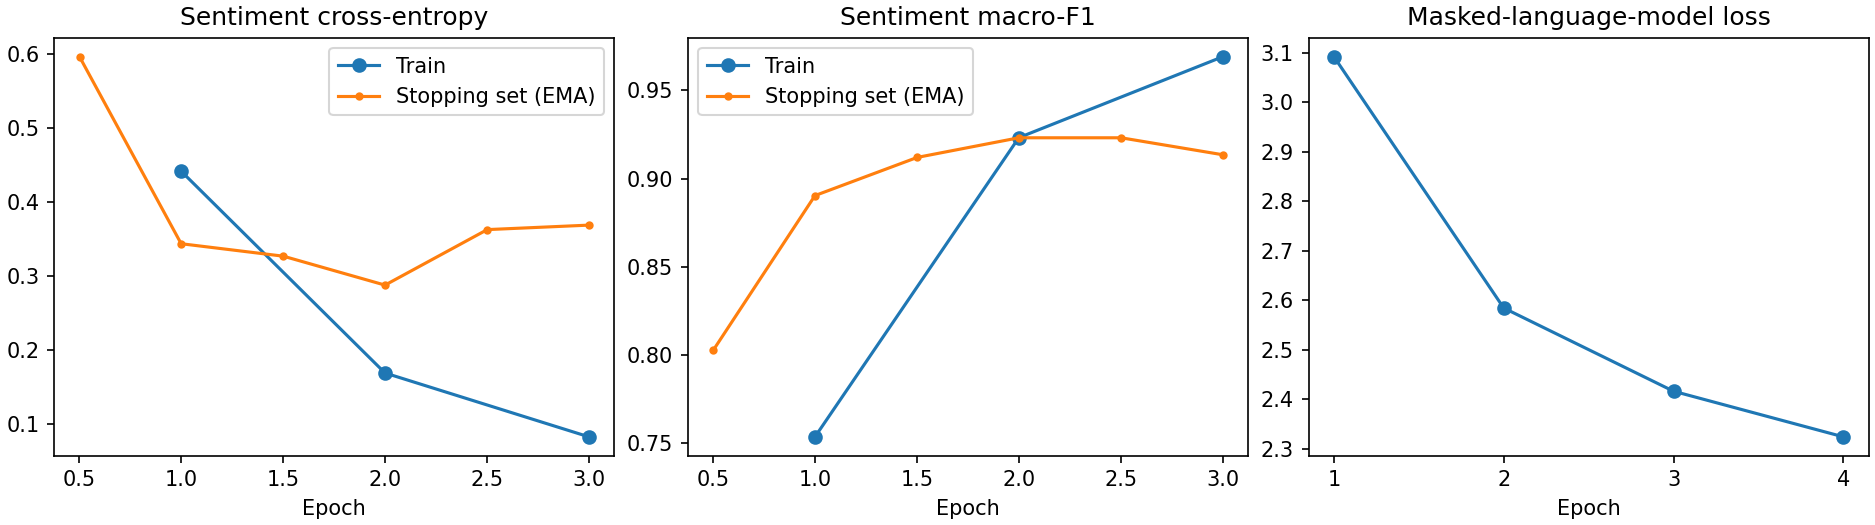

saved_models/member_2/training.png


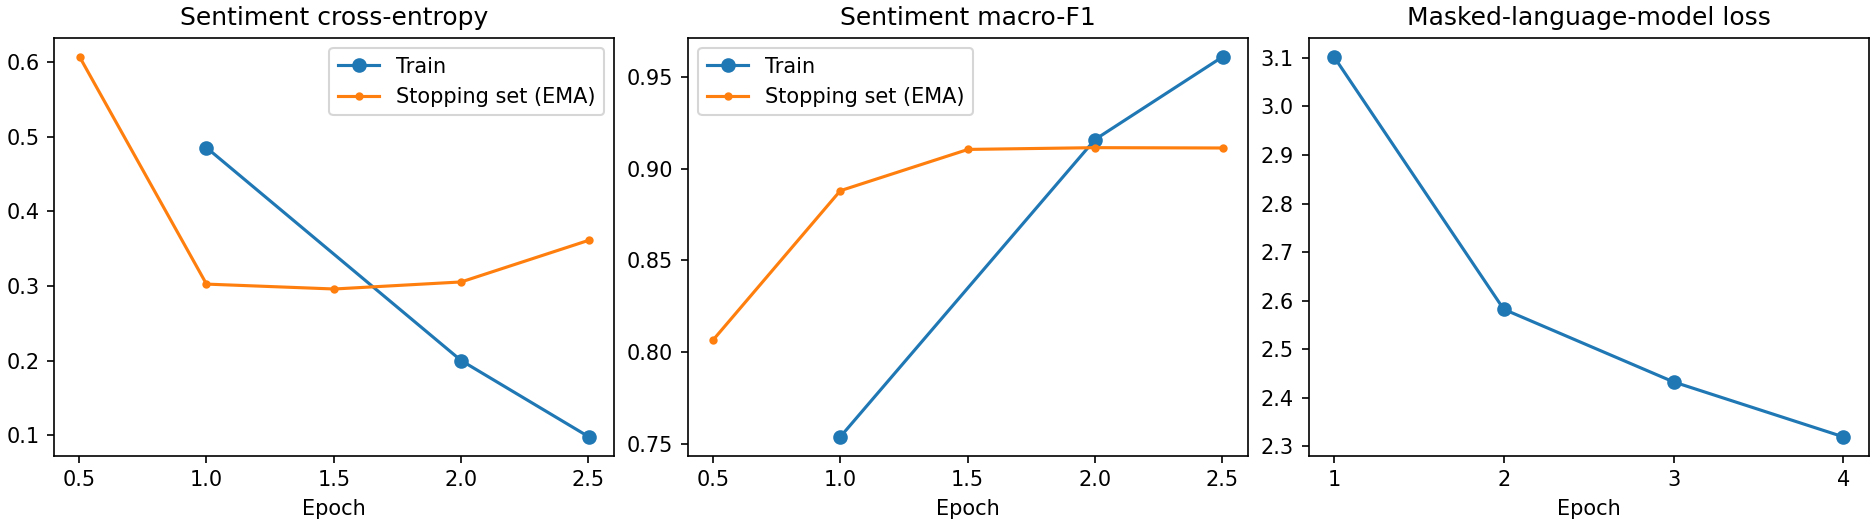

saved_models/member_3/training.png


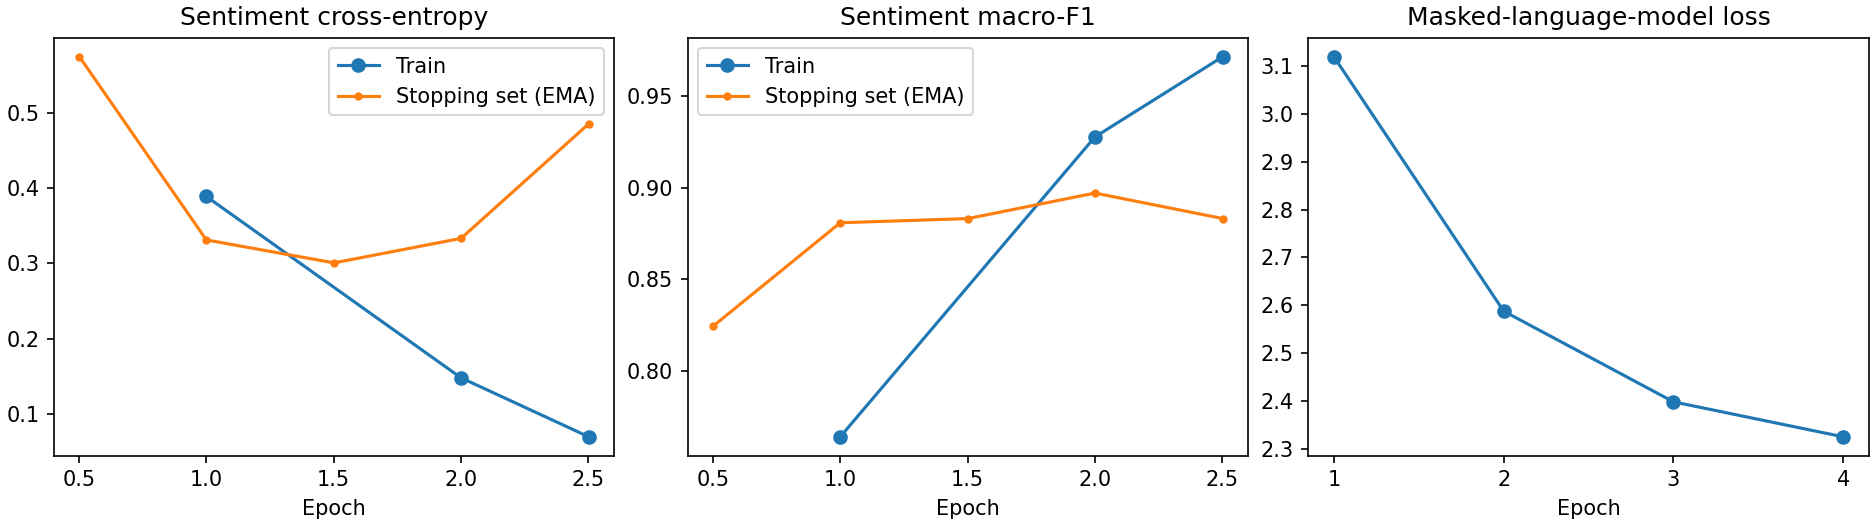

In [10]:
import json
from IPython.display import Image, JSON, display

run("evaluate", "--run-dir", holdout_dir, "--device", DEVICE)
display(JSON(data=json.loads((holdout_dir / "report.json").read_text(encoding="utf-8")), expanded=True))
for plot in sorted(holdout_dir.rglob("*.png")):
    print(plot.relative_to(holdout_dir))
    display(Image(filename=str(plot)))

## Test class offsets on the saved holdout

After running Configuration and Setup, point `offset_run` below to the completed training run or the extracted homework package containing `system.json`. Run this cell directly to evaluate the existing checkpoints. It fits offsets on one grouped half and measures the change on the other. Colab downloads `offset_report.txt`; the per-tweet probabilities CSV is saved alongside it.

In [ ]:
import csv
import sys
from itertools import product

import numpy as np
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold

# Set this to the extracted HW3_<student ID> folder if using your saved submission ZIP.
offset_run = holdout_dir
sys.path.insert(0, str(project))
import main as hw

if not (offset_run / "system.json").is_file():
    raise FileNotFoundError(f"Set offset_run to your trained folder containing system.json and saved_models. Checked {offset_run}")
hw.check_run(offset_run)
manifest = hw.read_json(offset_run / "splits.json")
packaged_data = offset_run / "dataset" / "dataset.csv"
tweets = hw.read_tweets(packaged_data if packaged_data.is_file() else data_dir / "dataset.csv", labeled=True)
if tweets.digest != manifest["dataset_sha256"] or list(hw.LABELS) != manifest["labels"]:
    raise ValueError("The labeled course CSV or class order differs from the training manifest.")
holdout_ids = manifest["test_ids"]
rows = np.flatnonzero(np.isin(tweets.ids, holdout_ids))
if len(rows) != len(holdout_ids) or len(rows) == 0:
    raise ValueError("The saved holdout IDs must be unique and present in the labeled course CSV.")
gold = tweets.labels[rows]
groups = tweets.normalized[rows]
split_seed = 113
splitter = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=split_seed)
tune, confirm = next(splitter.split(rows, gold, groups))
if set(groups[tune]) & set(groups[confirm]):
    raise RuntimeError("A normalized tweet appears in both halves.")

print(f"Scoring {len(rows)} saved holdout tweets with the three checkpoints...", flush=True)
scores, _, _, _ = hw.score_system(tweets.raw[rows], groups, offset_run, hw.choose_device(DEVICE))
probs = scores["two_readings"].astype(np.float64)
logp = np.log(np.maximum(probs, np.finfo(float).tiny))
baseline = probs.argmax(axis=1)
class_ids = np.arange(len(hw.LABELS))

# Search small offsets in log-probability units. Prefer the smallest adjustment in a tie.
best_offsets = np.zeros(3)
best_f1 = -1.0
for n, p in sorted(product(range(-4, 5), repeat=2), key=lambda pair: sum(v*v for v in pair)):
    candidate = np.array([0.0, n / 20, p / 20])
    labels = (logp[tune] + candidate).argmax(axis=1)
    score = f1_score(gold[tune], labels, labels=class_ids, average="macro", zero_division=0)
    if score > best_f1 + 1e-12:
        best_f1, best_offsets = score, candidate

adjusted = (logp + best_offsets).argmax(axis=1)
lines = [
    "HW3 class-offset experiment",
    f"Outer fold {manifest['outer_fold']} | {len(rows)} labeled holdout tweets | split seed {split_seed}",
    f"Dataset SHA-256 {tweets.digest}",
    f"Class order: {', '.join(hw.LABELS)}",
    "Grid: negative fixed at 0; neutral and positive each from -0.20 to +0.20 in steps of 0.05.",
    "Selection: highest tuning macro-F1, ties favor offsets closest to zero.",
    "Selected offsets: " + ", ".join(f"{name} {value:+.2f}" for name, value in zip(hw.LABELS, best_offsets)),
]
for name, part in (("Confirmation (unseen during offset selection)", confirm), ("Tuning", tune)):
    lines += ["", f"{name}: {len(part)} rows", "Metric         Baseline    Adjusted      Change"]
    before, after = [
        f1_score(gold[part], labels[part], labels=class_ids, average=None, zero_division=0)
        for labels in (baseline, adjusted)
    ]
    for label, a, b in zip(("Macro-F1", *hw.LABELS), [before.mean(), *before], [after.mean(), *after]):
        lines.append(f"{label:<12} {a:10.5f}  {b:10.5f}  {b-a:+10.5f}")
    fixed = (baseline[part] != gold[part]) & (adjusted[part] == gold[part])
    introduced = (baseline[part] == gold[part]) & (adjusted[part] != gold[part])
    lines.append(f"Predictions changed: {(baseline[part] != adjusted[part]).sum()} | mistakes fixed: {fixed.sum()} | new mistakes: {introduced.sum()}")
    for title, labels in (("Baseline", baseline), ("Adjusted", adjusted)):
        cm = confusion_matrix(gold[part], labels[part], labels=class_ids)
        lines.append(f"{title} confusion matrix (rows = gold, columns = predicted):\n{cm}")
lines += ["", "Changed confirmation tweets (ID | gold | baseline -> adjusted | tweet)"]
changed = confirm[baseline[confirm] != adjusted[confirm]]
for i in changed:
    row = rows[i]
    lines.append(f"{tweets.ids[row]} | {hw.LABELS[gold[i]]} | {hw.LABELS[baseline[i]]} -> {hw.LABELS[adjusted[i]]} | {' '.join(tweets.raw[row].split())}")
if not len(changed):
    lines.append("No confirmation labels changed.")

result_dir = runs / f"offset_experiment_fold_{manifest['outer_fold']:02d}"
result_dir.mkdir(parents=True, exist_ok=True)
txt = result_dir / "offset_report.txt"
txt.write_text("\n".join(lines) + "\n", encoding="utf-8")
part_names = np.full(len(rows), "confirmation", dtype=object)
part_names[tune] = "tuning"
with (result_dir / "holdout_probabilities.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["id", "split", "gold", *[f"p_{label}" for label in hw.LABELS], "baseline", "adjusted"])
    for i, row in enumerate(rows):
        writer.writerow([tweets.ids[row], part_names[i], hw.LABELS[gold[i]], *probs[i],
                         hw.LABELS[baseline[i]], hw.LABELS[adjusted[i]]])
print(txt.read_text(encoding="utf-8"))
print(f"Saved experiment files in {result_dir}")
if ON_COLAB:
    colab_files.download(str(txt))


## Optional 10-fold out-of-fold evaluation

Set `RUN_OOF = True` to evaluate all labeled rows. Each outer fold fits its own learned components with only that fold's outer training rows. Fold 2 can reuse the matching holdout run. The reference second reading changed pooled macro-F1 from 0.89931 to 0.90045 and neutral F1 from 0.82380 to 0.82491.

In [11]:
oof_options = (
    "--run-dir", oof_dir, "--reuse-holdout", holdout_dir, "--device", DEVICE,
)
if RUN_OOF:
    run("oof", *oof_options)
    display(JSON(data=json.loads((oof_dir / "report.json").read_text(encoding="utf-8")), expanded=True))
else:
    show_command(command("oof", *oof_options))

/usr/bin/python3 /content/Intro_to_AI_HW/IAI_HW3/main.py oof --data-dir /content/Intro_to_AI_HW/IAI_HW3/dataset --run-dir /content/Intro_to_AI_HW/IAI_HW3/runs/oof --reuse-holdout /content/Intro_to_AI_HW/IAI_HW3/runs/holdout_fold_02 --device cuda


## Generate and verify the submission files

Predict the benchmark in its original order. The packaging command reloads the packaged checkpoints and reproduces the submission. The notebook also compares the packaged CSV with the direct prediction, checks the header and ID sequence, and verifies the allowed labels. Submit the ZIP to E3 and upload the CSV to Kaggle yourself.

In [12]:
import csv

direct_predictions = holdout_dir / "benchmark_predictions.csv"
run("predict", "--run-dir", holdout_dir, "--output", direct_predictions, "--device", DEVICE)
run(
    "package", "--run-dir", holdout_dir, "--student-id", STUDENT_ID,
    "--output", delivery_dir, "--device", DEVICE,
)

submission = delivery_dir / "predictions.csv"
archive = delivery_dir / f"HW3_{STUDENT_ID}.zip"
if direct_predictions.read_bytes() != submission.read_bytes():
    raise ValueError("Direct and packaged predictions differ.")
with (data_dir / "benchmark.csv").open(encoding="utf-8-sig", newline="") as file:
    benchmark_ids = [row["id"] for row in csv.DictReader(file)]
with submission.open(encoding="utf-8", newline="") as file:
    predictions = csv.DictReader(file)
    if predictions.fieldnames != ["id", "label"]:
        raise ValueError(f"Unexpected CSV header {predictions.fieldnames}")
    rows = list(predictions)
submission_ids = [row["id"] for row in rows]
if submission_ids != benchmark_ids or len(set(submission_ids)) != len(submission_ids):
    raise ValueError("Submission IDs differ from the unique benchmark IDs in CSV order.")
if any(row["label"] not in {"negative", "neutral", "positive"} for row in rows):
    raise ValueError("The submission contains a label outside the three allowed sentiments.")
if not archive.is_file():
    raise FileNotFoundError(archive)
print(f"Validated {len(rows):,} predictions.")
print(f"E3 package {archive}")
print(f"Kaggle submission {submission}")
if ON_COLAB and DOWNLOAD_IN_COLAB:
    colab_files.download(str(submission))
    colab_files.download(str(archive))

/usr/bin/python3 /content/Intro_to_AI_HW/IAI_HW3/main.py predict --data-dir /content/Intro_to_AI_HW/IAI_HW3/dataset --run-dir /content/Intro_to_AI_HW/IAI_HW3/runs/holdout_fold_02 --output /content/Intro_to_AI_HW/IAI_HW3/runs/holdout_fold_02/benchmark_predictions.csv --device cuda
/usr/bin/python3 /content/Intro_to_AI_HW/IAI_HW3/main.py package --data-dir /content/Intro_to_AI_HW/IAI_HW3/dataset --run-dir /content/Intro_to_AI_HW/IAI_HW3/runs/holdout_fold_02 --student-id 113511195 --output /content/Intro_to_AI_HW/IAI_HW3/runs/delivery --device cuda
Validated 1,000 predictions.
E3 package /content/Intro_to_AI_HW/IAI_HW3/runs/delivery/HW3_113511195.zip
Kaggle submission /content/Intro_to_AI_HW/IAI_HW3/runs/delivery/predictions.csv


In [14]:
from google.colab import files
files.download(str(submission))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>